# Atividade 03 — Fontes antes e depois do tratamento

Para cada fonte: o dado como veio, o dado tratado pelo módulo de `pipeline/fontes/`, as validações registradas no `ResultadoFonte` e os casos concretos de erro ou de dado faltante que motivaram cada tratamento.

- **Fontes em lote (Atividade 02):** IBAMA, DETER e Lista Suja. O caderno lê o bruto em `data/raw/` e o parquet gerado por `python -m pipeline`; as validações vêm do relatório dessa execução.
- **Fontes sob demanda (Atividade 03):** SICAR, PRODES e AB+S. Cada consulta grava a resposta bruta em `data/raw/<fonte>/` com um `.meta.json` (URL, parâmetros, data UTC, SHA-256). A primeira execução vai à rede; as seguintes reaproveitam o que foi gravado.

CPF e CNPJ nunca aparecem: só o tamanho ou o HMAC-SHA256 de `pipeline/documentos.py`.

## 1. Configuração

In [1]:
import gzip
import json
import logging
import math
import sys
import tempfile
import uuid
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import shapely
from matplotlib.patches import Patch

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))
from pipeline import config, cruzamento, wfs  # noqa: E402
from pipeline.documentos import carregar_chave, somente_digitos  # noqa: E402
from pipeline.fontes import ab_s, inpe_deter, inpe_prodes, mte_lista_suja, sicar  # noqa: E402
from pipeline.validacao import ErroDeValidacao  # noqa: E402

warnings.filterwarnings("ignore")
logging.getLogger("pipeline").setLevel(logging.ERROR)
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 50)

CHAVE = carregar_chave()
HOJE = pd.Timestamp.today().normalize()
REF = pd.read_parquet(config.DADOS_PROCESSADOS / "ibge_municipios.parquet")
LOTE = json.loads((config.DADOS_PROCESSADOS / "relatorio_execucao.json").read_text())
FONTES_LOTE = {f["fonte"]: f for f in LOTE["fontes"]}


def validacoes(resultado, so_ocorrencias=False, codigos=None):
    """Tabela de validações de um ResultadoFonte (objeto ou dicionário do relatório do lote)."""
    linhas = resultado["validacoes"] if isinstance(resultado, dict) else [v.__dict__ for v in resultado.validacoes]
    t = pd.DataFrame(linhas)[["codigo", "severidade", "tratamento", "verificados", "ocorrencias"]]
    if codigos:
        t = t[t["codigo"].isin(codigos)]
    return t[t["ocorrencias"] > 0] if so_ocorrencias else t


def num(n):
    """Inteiro com separador de milhar brasileiro."""
    return f"{int(n):,}".replace(",", ".")


def desenhar(ax, geom, **kw):
    for parte in getattr(geom, "geoms", [geom]):
        if parte.geom_type == "Polygon":
            ax.fill(*parte.exterior.xy, **kw)
        elif hasattr(parte, "geoms"):
            desenhar(ax, parte, **kw)


def enquadrar(ax, geom, margem=0.003):
    x0, y0, x1, y1 = geom.buffer(margem).bounds
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)
    ax.set_aspect(1 / math.cos(math.radians((y0 + y1) / 2)))
    ax.tick_params(labelsize=7)


print(f"Execução do lote lida: {LOTE['inicio']} ({LOTE['comando']})")

Execução do lote lida: 2026-09-13 22:54:34 (python -m pipeline --atualizar --evidencia docs/evidencias)


## 2. IBAMA — Áreas Embargadas (CSV, lote)

O CSV é lido com todas as colunas como texto. O módulo `ibama_embargos` seleciona 16 colunas, cria o `id_embargo`, converte datas e área, padroniza município e bioma pela referência do IBGE e troca o CPF/CNPJ pelo HMAC. Colunas com nome ou documento do responsável não são mostradas.

In [2]:
colunas = ["NUM_TAD", "SER_TAD", "SEQ_TAD", "DAT_EMBARGO", "COD_MUNICIPIO_TAD", "QTD_AREA_EMBARGADA", "DES_TIPO_BIOMA"]
bruto = pd.read_csv(config.DADOS_BRUTOS / "areas_embargadas.csv", sep=";", dtype=str, nrows=3, usecols=colunas)
tratado = pd.read_parquet(config.DADOS_PROCESSADOS / "ibama_embargos.parquet",
                          columns=["id_embargo", "data_embargo", "cod_municipio", "municipio", "area_ha", "biomas",
                                   "documento_hash", "alertas"]).head(3)
tratado["documento_hash"] = tratado["documento_hash"].str[:12] + "..."
display(bruto, tratado)
validacoes(FONTES_LOTE["ibama_embargos"], so_ocorrencias=True)

,SEQ_TAD,NUM_TAD,SER_TAD,DAT_EMBARGO,COD_MUNICIPIO_TAD,QTD_AREA_EMBARGADA,DES_TIPO_BIOMA
0,1829644,28855,A,16/12/1987 15:40:00,4207205,NaN,NaN
1,1600976,278153,A,03/08/1988 14:45:00,5100805,"10,0000",Amazonia
2,1843657,0278399,A,09/08/1988 10:30:00,5107776,NaN,Amazonia


,id_embargo,data_embargo,cod_municipio,municipio,area_ha,biomas,documento_hash,alertas
0,28855-A-1829644,1987-12-16 15:40:00,4207205,Imaruí,NaN,<NA>,0d429ac4e8a6...,
1,278153-A-1600976,1988-08-03 14:45:00,5100805,Apiacás,10.0,Amazônia,7991c6796aed...,COORD_ZERO
2,0278399-A-1843657,1988-08-09 10:30:00,5107776,Santa Terezinha,NaN,Amazônia,80e16d881486...,


,codigo,severidade,tratamento,verificados,ocorrencias
4,IBAMA_DOC_AUSENTE,alerta,"registro mantido, sem vínculo por documento",91199,9233
5,IBAMA_DOC_TAMANHO_INVALIDO,alerta,documento anulado,91199,2
6,IBAMA_DOC_DV_INVALIDO,alerta,documento anulado,91199,164
8,IBAMA_DATA_EMBARGO_FUTURA,alerta,data anulada,91199,1
9,IBAMA_MUNICIPIO_DESCONHECIDO,alerta,mantido com nome e UF da própria base,91199,17
11,IBAMA_COORD_INCOMPLETA,alerta,coordenada anulada,91199,1087
12,IBAMA_COORD_ZERO,alerta,coordenada anulada,91199,3180
13,IBAMA_COORD_FORA_BRASIL,alerta,coordenada anulada,91199,255
15,IBAMA_AREA_NAO_POSITIVA,alerta,área anulada,91199,406
16,IBAMA_BIOMA_NORMALIZADO,correcao,"itens únicos, ordenados e acentuados",56469,44619


**CPF/CNPJ lido como número.** Sem instrução de tipo, o pandas lê o documento como número e apaga os zeros à esquerda: o documento muda de tamanho e deixa de casar com outras bases, sem aviso. A tabela mostra só quantos documentos têm cada número de dígitos.

In [3]:
arquivo = config.DADOS_BRUTOS / "areas_embargadas.csv"
como_numero = pd.read_csv(arquivo, sep=";", usecols=["CPF_CNPJ_EMBARGADO"], low_memory=False)["CPF_CNPJ_EMBARGADO"]
como_texto = somente_digitos(pd.read_csv(arquivo, sep=";", usecols=["CPF_CNPJ_EMBARGADO"], dtype=str)["CPF_CNPJ_EMBARGADO"])
print("tipo inferido sem instrução:", como_numero.dtype)
print("documentos que começam com zero:", num(como_texto.str.startswith("0").sum()))
pd.DataFrame({"lido como número": como_numero.dropna().astype("int64").astype(str).str.len().value_counts(),
              "lido como texto": como_texto.dropna().str.len().value_counts()}
             ).fillna(0).astype(int).rename_axis("dígitos").sort_index()

tipo inferido sem instrução: float64
documentos que começam com zero: 25.490


,lido como número,lido como texto
dígitos,,
1,6,0
6,5,0
7,31,0
8,322,0
9,3266,0
10,15609,0
11,51235,70426
12,308,0
13,5901,2


## 3. DETER — alertas de desmatamento (WFS, lote)

Cada feature é o trecho de um alerta dentro de um município. O `gid` não identifica o alerta: um alerta dividido entre municípios repete o `gid`, e o serviço reutiliza o mesmo `gid` em alertas de datas diferentes. O módulo cria `id_alerta` = camada + `gid` + hash do conteúdo (gid, data, município, geometria) e descarta feature sem `gid`.

In [4]:
manifesto = json.loads((config.DADOS_BRUTOS / "inpe_deter/cerrado/desde_2021-01-01/manifesto.json").read_text())
particao = manifesto["particoes"][-2]
resposta = json.loads(gzip.decompress((config.DADOS_BRUTOS / "inpe_deter/cerrado/desde_2021-01-01" / particao["arquivo"]).read_bytes()))
bruto = pd.DataFrame([f["properties"] for f in resposta["features"]])
display(bruto[["gid", "classname", "view_date", "uf", "municipality", "areamunkm"]].head(3))
alertas = pd.read_parquet(config.DADOS_PROCESSADOS / "inpe_deter_alertas.parquet",
                          columns=["id_alerta", "camada", "gid", "classe", "data_imagem", "uf", "cod_municipio",
                                   "municipio", "area_km2", "alertas"])
alertas.head(3)

,gid,classname,view_date,uf,municipality,areamunkm
0,64294_curr,DESMATAMENTO_CR,2026-08-17,MT,CAMPOS DE JÚLIO,0.089516
1,64323_curr,DESMATAMENTO_CR,2026-08-20,MT,SÃO FÉLIX DO ARAGUAIA,0.258180
2,63776_curr,DESMATAMENTO_CR,2026-08-13,MA,BARRA DO CORDA,0.358843


,id_alerta,camada,gid,classe,data_imagem,uf,cod_municipio,municipio,area_km2,alertas
0,amazonia:42556_hist:84440580ae19,amazonia,42556_hist,DESMATAMENTO_CR,2021-01-09,RO,1100205,Porto Velho,0.070138,
1,amazonia:42647_hist:3102ba180bfe,amazonia,42647_hist,DESMATAMENTO_CR,2021-01-16,PA,1506195,Rurópolis,0.174823,
2,amazonia:42477_hist:bc2c64cd4cbe,amazonia,42477_hist,DESMATAMENTO_CR,2021-01-07,PA,1500602,Altamira,0.103463,


In [5]:
por_gid = alertas.groupby(["camada", "gid"]).agg(linhas=("id_alerta", "size"), datas=("data_imagem", "nunique"))
divididos = ((por_gid["linhas"] > 1) & (por_gid["datas"] == 1)).sum()
reutilizados = ((por_gid["linhas"] > 1) & (por_gid["datas"] > 1)).sum()
print(f"{num(len(alertas))} alertas tratados; {num(len(por_gid))} pares (camada, gid)")
print(f"gid de alerta dividido entre municípios: {num(divididos)}; gid reutilizado em datas diferentes: {num(reutilizados)}")
print("id_alerta é único:", alertas["id_alerta"].is_unique)
exemplo = por_gid[por_gid["datas"] > 1].index[0]
display(alertas.set_index(["camada", "gid"]).loc[[exemplo], ["id_alerta", "data_imagem", "municipio", "area_km2"]])
validacoes(FONTES_LOTE["inpe_deter"], codigos=["DETER_GID_AUSENTE", "DETER_GEOM_AUSENTE", "DETER_ALERTA_DUPLICADO",
                                               "DETER_MUNICIPIO_APELIDO", "DETER_GEOM_INVALIDA", "DETER_GEOMETRIA_REPETIDA"])

233.777 alertas tratados; 178.599 pares (camada, gid)
gid de alerta dividido entre municípios: 1.849; gid reutilizado em datas diferentes: 39.890
id_alerta é único: True


id_alerta data_imagem municipio  area_km2
camada   gid                                                                         
amazonia 10000_hist  amazonia:10000_hist:66b67662e8d5  2021-09-22   Trairão  0.348734
         10000_hist  amazonia:10000_hist:df3a382f6858  2023-09-29   Amajari  0.347491

,codigo,severidade,tratamento,verificados,ocorrencias
10,DETER_GID_AUSENTE,descarte,registro vai para descartados,233777,0
11,DETER_GEOM_AUSENTE,descarte,registro vai para descartados,233777,0
12,DETER_ALERTA_DUPLICADO,descarte,registro vai para descartados,233777,0
18,DETER_MUNICIPIO_APELIDO,correcao,nome substituído pelo oficial antes de buscar ...,233777,90
22,DETER_GEOM_INVALIDA,alerta,geometria mantida sem correção,233777,17841
23,DETER_GEOMETRIA_REPETIDA,alerta,mantido,233777,6


## 4. Lista Suja — Cadastro de Empregadores (PDF, lote)

O PDF é lido página a página com `pdfplumber`. Cabeçalhos repetidos e títulos de página saem; o nome do empregador sai; o documento vira HMAC. Abaixo, a primeira linha de registro como foi extraída (com nome e documento ocultados) e a mesma linha tratada.

In [6]:
textos, tabelas = mte_lista_suja.extrair(config.DADOS_BRUTOS / "lista_suja.pdf")
print(next(linha for linha in textos[0].splitlines() if "atualizado" in linha))
linha = next(l for l in tabelas[0] if (l[0] or "").strip().isdigit())
extraida = dict(zip(mte_lista_suja.CABECALHO_ESPERADO, [mte_lista_suja._limpar(c) for c in linha]))
extraida["Empregador"] = "[oculto]"
extraida["CNPJ/CPF"] = f"[oculto: {len(somente_digitos(pd.Series([linha[4]])).iloc[0])} dígitos]"
display(pd.DataFrame([extraida]))
lista = pd.read_parquet(config.DADOS_PROCESSADOS / "mte_lista_suja.parquet")
lista["documento_hash"] = lista["documento_hash"].str[:12] + "..."
display(lista[lista["id_registro"] == int(extraida["ID"])])
validacoes(FONTES_LOTE["mte_lista_suja"], codigos=["LS_LINHA_NAO_RECONHECIDA", "LS_DOC_FORMATO_INVALIDO",
                                                   "LS_DOC_DV_INVALIDO", "LS_DOC_REPETIDO", "LS_UF_INVALIDA",
                                                   "LS_INCLUSAO_MULTIPLOS_PERIODOS"])

Atualização periódica de 6 de abril de 2026. Cadastro atualizado em 04/09/2026.


,ID,Ano da ação fiscal,UF,Empregador,CNPJ/CPF,Estabelecimento,Trabalhadores envolvidos,CNAE,Decisão administrativa de procedência,Inclusão no Cadastro de Empregadores
0,1,2024,SP,[oculto],[oculto: 14 dígitos],"ROD. PREFEITO JOAQUIM SIMÃO, KM 735, CENTRO, I...",2,4399-1/03,15/05/2025,06/10/2025


,id_registro,documento_hash,tipo_documento,uf,estabelecimento,cnae,cnae_agropecuaria,trabalhadores_envolvidos,ano_acao_fiscal,data_decisao,data_inclusao,data_inclusao_ultima,data_atualizacao_cadastro,alertas
0,1,981e7bbea88a...,CNPJ,SP,"ROD. PREFEITO JOAQUIM SIMÃO, KM 735, CENTRO, I...",4399-1/03,False,2,2024,2025-05-15,2025-10-06,2025-10-06,2026-09-04,


,codigo,severidade,tratamento,verificados,ocorrencias
4,LS_LINHA_NAO_RECONHECIDA,descarte,linha vai para descartados,714,0
7,LS_DOC_FORMATO_INVALIDO,alerta,documento anulado,579,0
8,LS_DOC_DV_INVALIDO,alerta,documento anulado,579,0
9,LS_DOC_REPETIDO,alerta,mantido (estabelecimentos diferentes),579,22
10,LS_UF_INVALIDA,alerta,UF anulada,579,3
16,LS_INCLUSAO_MULTIPLOS_PERIODOS,correcao,primeira e última data extraídas em colunas se...,579,10


## 5. SICAR — CAR por município (sob demanda)

Uma requisição por município aos 10 maiores produtores de café de MG (`config.MUNICIPIOS_CAFE_MG`), pela sessão com o adaptador de TLS do módulo `sicar` (certificado verificado). A coleta só segue se o recebido for igual ao `numberMatched` anunciado; a sobreposição é medida no conjunto dos 10 municípios.

In [7]:
car, r_car = sicar.consultar_municipios(config.MUNICIPIOS_CAFE_MG)
coleta = pd.DataFrame(r_car.entrada["requisicoes"])
print(f"anunciado {num(coleta['anunciado'].sum())}; recebido {num(coleta['recebido'].sum())}; tratado {num(len(car))} imóveis")
primeira = json.loads(gzip.decompress((config.RAIZ / coleta.loc[0, "arquivo"]).read_bytes()))
display(sicar.resposta_para_tabela(primeira).drop(columns="geom").head(3))
display(car.drop(columns="geometria_wkt").head(3))
validacoes(r_car)

anunciado 33.452; recebido 33.452; tratado 33.452 imóveis


,cod_imovel,status_imovel,dat_criacao,data_atualizacao,area,condicao,uf,municipio,cod_municipio_ibge,m_fiscal,tipo_imovel,id_feature
0,MG-3119302-0174C8565DE64AC990D8870C1AD782EF,AT,2023-06-16T13:00:51.779Z,2025-03-07T16:10:06.509Z,0.0686,Aguardando análise,MG,Patrocínio,3148103,0.0017,IRU,sicar_imoveis_mg.11684651
1,MG-3119302-020148BBF4924F94BD6B228C28337DCF,AT,2023-06-16T13:21:57.372Z,2025-03-07T16:10:06.509Z,0.0564,Aguardando análise,MG,Patrocínio,3148103,0.0014,IRU,sicar_imoveis_mg.11684766
2,MG-3119302-1920F5E531274FF6826C3C2D970B6EBD,AT,2023-06-16T12:39:03.815Z,2025-03-07T16:10:06.509Z,0.0462,Aguardando análise,MG,Patrocínio,3148103,0.0012,IRU,sicar_imoveis_mg.11684550


,cod_imovel,uf,cod_municipio,municipio,tipo_imovel,status_imovel,condicao,area_declarada_ha,area_geom_ha,m_fiscal,data_criacao,data_atualizacao,fracao_coberta_por_outros,alertas
0,MG-3119302-0174C8565DE64AC990D8870C1AD782EF,MG,3148103,Patrocínio,IRU,AT,Aguardando análise,0.0686,0.068796,0.0017,2023-06-16 13:00:51.779000+00:00,2025-03-07 16:10:06.509000+00:00,0.003201,PREFIXO_MUNICIPIO_DIVERGENTE
1,MG-3119302-020148BBF4924F94BD6B228C28337DCF,MG,3148103,Patrocínio,IRU,AT,Aguardando análise,0.0564,0.056567,0.0014,2023-06-16 13:21:57.372000+00:00,2025-03-07 16:10:06.509000+00:00,0.000000,PREFIXO_MUNICIPIO_DIVERGENTE
2,MG-3119302-1920F5E531274FF6826C3C2D970B6EBD,MG,3148103,Patrocínio,IRU,AT,Aguardando análise,0.0462,0.046374,0.0012,2023-06-16 12:39:03.815000+00:00,2025-03-07 16:10:06.509000+00:00,0.000000,PREFIXO_MUNICIPIO_DIVERGENTE


,codigo,severidade,tratamento,verificados,ocorrencias
0,CAR_ESTRUTURA_RESPOSTA,erro,interrompe a consulta,10,0
1,CAR_PARTICAO_INCOMPLETA,erro,interrompe a consulta; repetir,10,0
2,CAR_CRS_INESPERADO,erro,interrompe a consulta,10,0
3,CAR_CODIGO_INVALIDO,descarte,registro vai para descartados,33452,0
4,CAR_DUPLICADO,descarte,registro vai para descartados,33452,0
5,CAR_STATUS_DESCONHECIDO,descarte,registro vai para descartados,33452,0
6,CAR_GEOM_AUSENTE,descarte,registro vai para descartados,33452,0
7,CAR_GEOM_INVALIDA,correcao,shapely.make_valid antes de medir,33452,13
8,CAR_PREFIXO_MUNICIPIO_DIVERGENTE,alerta,mantido cod_municipio_ibge; cruzar sempre pela...,33452,54
9,CAR_FORA_DO_MUNICIPIO,alerta,mantido; atribuir o município pela geometria q...,33452,298


**Ordem dos eixos.** O filtro espacial sem SRS espera (latitude, longitude); a resposta vem em (longitude, latitude). Com a ordem trocada o serviço responde zero, sem erro. Duas contagens (`resultType=hits`) no retângulo de um imóvel conhecido:

In [8]:
limites = sicar.geometrias(car.head(1))[0].bounds  # (lon_min, lat_min, lon_max, lat_max)
certo = wfs.filtro_bbox(sicar.CAMPO_GEOMETRIA, limites)
trocado = "BBOX({},{},{},{},{})".format(sicar.CAMPO_GEOMETRIA, *limites)
for rotulo, cql in (("lat, lon (config.ORDEM_EIXOS_FILTRO)", certo), ("lon, lat", trocado)):
    print(f"{rotulo:38} {cql:70} -> {wfs.contar(config.URL_WFS_SICAR, sicar.camada('MG'), cql, sicar.sessao())}")

lat, lon (config.ORDEM_EIXOS_FILTRO)   BBOX(geo_area_imovel,-18.89185255,-46.82308674,-18.89154803,-46.8227005) -> 2


lon, lat                               BBOX(geo_area_imovel,-46.82308674,-18.89185255,-46.8227005,-18.89154803) -> 0


**CAR sobreposto.** O SICAR aceita perímetros sobrepostos, e o status `AT` não indica que a sobreposição foi conferida. Exemplo: um imóvel com 95% ou mais da área coberta por outros CARs e os imóveis que o cobrem.

CAR_SOBREPOSTO_95: 6.727 de 33.452 (20.11%); desses, 5.537 com status AT, 5.471 deles ainda 'Aguardando análise'
status no recorte: {'AT': '28.428', 'PE': '4.539', 'CA': '476', 'SU': '9'} | condição 'Aguardando análise': 24.559


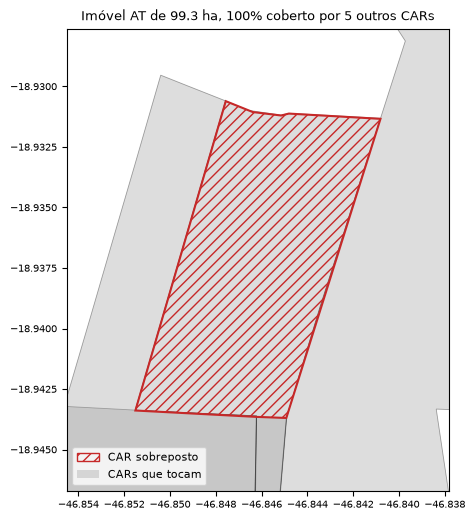

In [9]:
sobrepostos = car[car["alertas"].str.contains("SOBREPOSTO_95")]
print(f"CAR_SOBREPOSTO_95: {num(len(sobrepostos))} de {num(len(car))} ({len(sobrepostos) / len(car):.2%}); "
      f"desses, {num((sobrepostos['status_imovel'] == 'AT').sum())} com status AT, "
      f"{num(((sobrepostos['status_imovel'] == 'AT') & (sobrepostos['condicao'] == 'Aguardando análise')).sum())} "
      "deles ainda 'Aguardando análise'")
print("status no recorte:", {k: num(v) for k, v in car["status_imovel"].value_counts().items()},
      "| condição 'Aguardando análise':", num((car["condicao"] == "Aguardando análise").sum()))
alvo = sobrepostos[(sobrepostos["cod_municipio"] == "3148103") & sobrepostos["area_geom_ha"].between(20, 200)].iloc[0]
g_alvo = shapely.from_wkt(alvo["geometria_wkt"])
geoms = sicar.geometrias(car)
vizinhos = car[shapely.intersects(geoms, g_alvo) & (car["cod_imovel"] != alvo["cod_imovel"])]
fig, ax = plt.subplots(figsize=(6, 6))
for _, v in vizinhos.iterrows():
    desenhar(ax, shapely.from_wkt(v["geometria_wkt"]), facecolor="#9e9e9e", alpha=0.35, edgecolor="black", linewidth=0.6)
desenhar(ax, g_alvo, facecolor="none", edgecolor="#c62828", hatch="///", linewidth=1.5)
enquadrar(ax, g_alvo)
ax.set_title(f"Imóvel {alvo['status_imovel']} de {alvo['area_geom_ha']:.1f} ha, {alvo['fracao_coberta_por_outros']:.0%} coberto "
             f"por {len(vizinhos)} outros CARs", fontsize=9)
ax.legend(handles=[Patch(facecolor="none", edgecolor="#c62828", hatch="///", label="CAR sobreposto"),
                   Patch(facecolor="#9e9e9e", alpha=0.35, label="CARs que tocam")], loc="lower left", fontsize=8)
plt.show()

## 6. PRODES — incremento anual (sob demanda)

O PRODES é consultado por bioma e por retângulo ou UF, um ano PRODES por requisição. A UF vem por extenso no Cerrado e é normalizada para a sigla; `main_class` diferente de `DESMATAMENTO` é descartado; geometria inválida é corrigida; `publish_year` é ignorado porque repete 01/01 do `year`. Primeiro, a ordem dos eixos no retângulo de Patrocínio:

In [10]:
camada = config.CAMADAS_PRODES["cerrado"]
url_prodes = config.URL_WFS_INPE.format(workspace=camada["workspace"])
patrocinio = sicar.malha_municipio("3148103").bounds
for rotulo, cql in (("lat, lon", wfs.filtro_bbox("geom", patrocinio)),
                    ("lon, lat", "BBOX(geom,{},{},{},{})".format(*patrocinio))):
    print(f"{rotulo}: {cql} -> {wfs.contar(url_prodes, camada['tipo'], cql)} polígonos")

lat, lon: BBOX(geom,-19.2774,-47.3907,-18.6932,-46.7502) -> 3596 polígonos


lon, lat: BBOX(geom,-47.3907,-19.2774,-46.7502,-18.6932) -> 0 polígonos


In [11]:
prodes, r_prodes = inpe_prodes.consultar("cerrado", uf="MG", desde=2019)
req = pd.DataFrame(r_prodes.entrada["requisicoes"])[["ano", "cql", "anunciado", "recebido"]]
display(req)
bruto = inpe_prodes.resposta_para_tabela(json.loads(gzip.decompress((config.RAIZ / r_prodes.entrada["requisicoes"][2]["arquivo"]).read_bytes())))
display(bruto.drop(columns="geom").head(3), prodes.drop(columns="geometria_wkt").head(3))
validacoes(r_prodes)

,ano,cql,anunciado,recebido
0,2019,state='MINAS GERAIS' AND year=2019,5551,5551
1,2020,state='MINAS GERAIS' AND year=2020,8657,8657
2,2021,state='MINAS GERAIS' AND year=2021,10368,10368
3,2022,state='MINAS GERAIS' AND year=2022,10254,10254
4,2023,state='MINAS GERAIS' AND year=2023,8360,8360
5,2024,state='MINAS GERAIS' AND year=2024,6374,6374
6,2025,state='MINAS GERAIS' AND year=2025,7144,7144
7,2026,state='MINAS GERAIS' AND year=2026,0,0


,uuid,state,main_class,class_name,year,image_date,publish_year,area_km,satellite,sensor,id_feature
0,8e1b97b1-389a-4b26-bff6-a0c3ca769495,MINAS GERAIS,DESMATAMENTO,d2021,2021,2021-07-12,2021-01-01,0.016740,Landsat8,OLI,yearly_deforestation.8e1b97b1-389a-4b26-bff6-a...
1,2906d3aa-5235-4a71-85dc-d41a49563274,MINAS GERAIS,DESMATAMENTO,d2021,2021,2021-08-22,2021-01-01,0.030732,Landsat8,OLI,yearly_deforestation.2906d3aa-5235-4a71-85dc-d...
2,7552af95-e6fb-4ced-a99e-62f2252ff410,MINAS GERAIS,DESMATAMENTO,d2021,2021,2021-07-12,2021-01-01,0.035457,Landsat8,OLI,yearly_deforestation.7552af95-e6fb-4ced-a99e-6...


,uuid,bioma,ano_prodes,data_imagem,uf,classe,area_km2_fonte,area_km2,satelite,sensor,alertas
0,abde8252-3fe6-4abe-9299-d39f3302ad6c,cerrado,2019,2019-09-11,MG,d2019,0.084062,0.086435,Landsat8,OLI,DATA_FORA_DO_ANO_PRODES
1,1659eab6-5434-4a1d-8190-355507958703,cerrado,2019,2019-09-11,MG,d2019,0.050392,0.048691,Landsat8,OLI,DATA_FORA_DO_ANO_PRODES
2,5397eb56-d3fa-44be-ac3a-9fa0669f6a17,cerrado,2019,2019-09-11,MG,d2019,0.065431,0.065526,Landsat8,OLI,DATA_FORA_DO_ANO_PRODES


,codigo,severidade,tratamento,verificados,ocorrencias
0,PRODES_ESTRUTURA_RESPOSTA,erro,interrompe a consulta,8,0
1,PRODES_PARTICAO_INCOMPLETA,erro,interrompe a consulta; repetir,8,0
2,PRODES_CRS_INESPERADO,erro,interrompe a consulta,8,0
3,PRODES_UUID_AUSENTE,descarte,registro vai para descartados,56708,0
4,PRODES_UUID_DUPLICADO,descarte,registro vai para descartados,56708,0
5,PRODES_CLASSE_FORA_DO_DOMINIO,descarte,registro vai para descartados,56708,0
6,PRODES_GEOM_AUSENTE,descarte,registro vai para descartados,56708,0
7,PRODES_GEOM_INVALIDA,correcao,shapely.make_valid antes de qualquer interseção,56708,4966
8,PRODES_UF_NORMALIZADA,correcao,convertida para a sigla,56708,56708
9,PRODES_UF_INVALIDA,alerta,UF anulada,56708,0


**`image_date` × `year`.** O ano PRODES vai de 01/08 do ano anterior a 31/07; a imagem do período seco muitas vezes é de agosto ou setembro. A regra da data de corte usa `image_date`.

In [12]:
datas = prodes.groupby("ano_prodes").agg(poligonos=("uuid", "size"), area_km2_fonte=("area_km2_fonte", "sum"),
                                         primeira=("data_imagem", "min"),
                                         mediana=("data_imagem", "median"), ultima=("data_imagem", "max"),
                                         fora_do_ano=("alertas", lambda s: s.str.contains("DATA_FORA_DO_ANO").sum()))
datas["imagem_ate_31_12_2020"] = prodes.groupby("ano_prodes")["data_imagem"].apply(lambda d: (d <= config.DATA_CORTE_EUDR).sum())
datas

,poligonos,area_km2_fonte,primeira,mediana,ultima,fora_do_ano,imagem_ate_31_12_2020
ano_prodes,,,,,,,
2019,5551,475.897916,2019-07-02,2019-08-17,2019-09-11,4041,5551
2020,8657,620.730446,2020-07-02,2020-08-19,2020-10-08,6189,8657
2021,10368,800.637542,2021-07-05,2021-08-22,2021-09-16,6673,0
2022,10254,801.367182,2022-07-06,2022-07-24,2022-09-11,2664,0
2023,8360,704.700548,2023-06-30,2023-07-26,2023-09-25,3759,0
2024,6374,509.278409,2024-07-12,2024-08-11,2024-08-25,4357,0
2025,7144,508.149182,2025-07-11,2025-08-12,2025-08-28,4763,0


**DETER × PRODES no Cerrado de MG.** Alertas DETER de MG desde 01/08/2020, consultados por ano PRODES com o mesmo tratamento do lote, e a regra de `inpe_prodes.confirmar_alertas` (limiar de 10% do alerta).

In [13]:
deter_mg, _, r_deter = inpe_deter.consultar_recorte("cerrado", "MG", "2020-08-01", (HOJE + pd.Timedelta(days=1)).strftime("%Y-%m-%d"), REF, HOJE)
conf = inpe_prodes.confirmar_alertas(deter_mg, prodes)
conf["ano_prodes_alerta"] = inpe_prodes.ano_prodes(conf["data_imagem"])
ultimo = int(prodes["ano_prodes"].max())
display(pd.crosstab(conf["ano_prodes_alerta"], conf["situacao"], margins=True, margins_name="total"))
consolidados = conf[(conf["ano_prodes_alerta"] <= ultimo) & (conf["situacao"] != "geometria sem área")]
resumo = consolidados["situacao"].value_counts().to_frame("alertas")
resumo["proporcao"] = (resumo["alertas"] / len(consolidados)).map("{:.1%}".format)
area = consolidados.groupby("situacao")["area_alerta_km2"].sum()
resumo["proporcao_da_area"] = (area / area.sum()).map("{:.1%}".format)
print(f"Anos consolidados (até {ultimo}): {num(len(consolidados))} alertas")
display(resumo)
janela = conf[(conf["data_imagem"] >= "2020-08-01") & (conf["data_imagem"] <= config.DATA_CORTE_EUDR)]
pelo_2021 = janela[janela["situacao"] == "confirmado"]["anos_prodes"].str.split(";").map(lambda a: "2021" in a).sum()
print(f"Imagem entre 01/08 e 31/12/2020 (antes do corte): {len(janela)} alertas; {pelo_2021} confirmados pelo PRODES 2021")

situacao,aguardando consolidação,confirmado,geometria sem área,já suprimido antes,não confirmado,total
ano_prodes_alerta,,,,,,
2021,0,681,1,188,131,1001
2022,0,453,0,141,121,715
2023,0,652,2,122,65,841
2024,0,1078,1,301,319,1699
2025,0,1043,0,183,134,1360
2026,2968,17,1,364,0,3350
2027,348,0,0,18,0,366
total,3316,3924,5,1317,770,9332


Anos consolidados (até 2025): 5.612 alertas


,alertas,proporcao,proporcao_da_area
situacao,,,
confirmado,3907,69.6%,71.9%
já suprimido antes,935,16.7%,13.4%
não confirmado,770,13.7%,14.7%


Imagem entre 01/08 e 31/12/2020 (antes do corte): 412 alertas; 166 confirmados pelo PRODES 2021


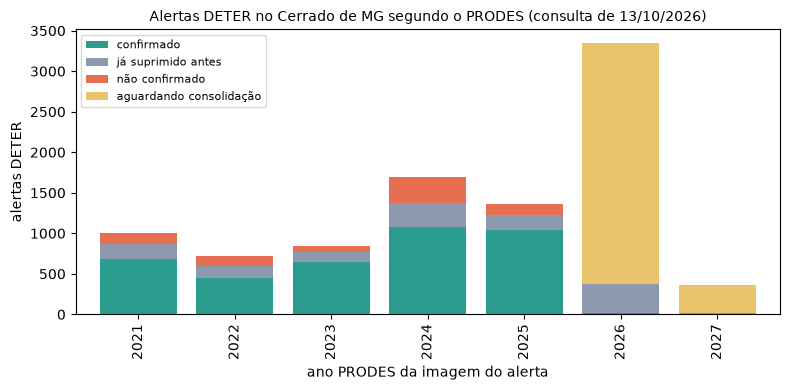

In [14]:
cores = {"confirmado": "#2a9d8f", "já suprimido antes": "#8d99ae", "não confirmado": "#e76f51",
         "aguardando consolidação": "#e9c46a"}
matriz = pd.crosstab(conf["ano_prodes_alerta"], conf["situacao"]).reindex(columns=list(cores), fill_value=0)
ax = matriz.plot.bar(stacked=True, color=list(cores.values()), figsize=(8, 4), width=0.8)
ax.set_xlabel("ano PRODES da imagem do alerta"); ax.set_ylabel("alertas DETER")
ax.set_title(f"Alertas DETER no Cerrado de MG segundo o PRODES (consulta de {HOJE:%d/%m/%Y})", fontsize=10)
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

## 7. AB+S — validação do relatório (sob demanda)

O código de autenticidade do relatório é validado antes da consulta: a API devolve 404 ou 500 para texto malformado, o que seria registrado como "relatório inexistente". Com formato válido, os três endpoints são consultados uma vez; 404 vira "não localizado na consulta pública em [data]".

In [15]:
try:
    ab_s.consultar("nao-e-um-uuid", CHAVE)
except ErroDeValidacao as e:
    print("rejeitado sem consultar:", e)

aleatorio = str(uuid.uuid4())  # inexistente por construção
respostas, r_abs = ab_s.consultar(aleatorio, CHAVE)
display(respostas[["endpoint", "status_http", "situacao", "mensagem"]])
validacoes(r_abs)

rejeitado sem consultar: ABS_UUID_FORMATO_INVALIDO: Código de autenticidade fora do formato UUID (8-4-4-4-12 hex) (1 ocorrências)


,endpoint,status_http,situacao,mensagem
0,qualificacao,404,não localizado na consulta pública em 14/10/2026,Não foi encontrado nenhum registro na entidade...
1,habilitacao,404,não localizado na consulta pública em 14/10/2026,Não foi encontrado nenhum registro na entidade...
2,area-producao,404,não localizado na consulta pública em 14/10/2026,Não foi encontrado nenhum registro na entidade...


,codigo,severidade,tratamento,verificados,ocorrencias
0,ABS_UUID_FORMATO_INVALIDO,erro,não consulta: a API devolveria 404 ou 500 como...,1,0
1,ABS_RESPOSTA_NAO_JSON,alerta,registrado como erro do serviço,3,0
2,ABS_NAO_LOCALIZADO,alerta,registrar 'não localizado na consulta pública ...,3,3
3,ABS_ERRO_SERVICO,alerta,repetir a consulta depois,3,0
4,ABS_DOCUMENTO_PSEUDONIMIZADO,correcao,trocado por HMAC-SHA256 antes de gravar,3,0


**Extração do código de um PDF.** Sem relatório real em PDF, o teste usa um PDF sintético com o rodapé do relatório e o código do relatório de demonstração. Depois, os 9 critérios do relatório e a cobertura do projeto com fontes abertas.

In [16]:
with tempfile.TemporaryDirectory() as pasta:
    for rodape in ("Código de autenticidade: 57e267ec-70b4-4d46-bef8-535b8b49b5f9", None):
        fig = plt.figure(figsize=(8.27, 11.69))
        fig.text(0.08, 0.95, "RELATÓRIO DE VERIFICAÇÃO (documento sintético, não emitido)", fontsize=11)
        if rodape:
            fig.text(0.08, 0.20, rodape, fontsize=9)
        pdf = Path(pasta) / "relatorio.pdf"
        fig.savefig(pdf, format="pdf"); plt.close(fig)
        extraido = ab_s.extrair_uuid(pdf)
        print(f"{'com' if rodape else 'sem'} código no rodapé -> {extraido}; formato:", ab_s.validar_uuid(extraido or ""))
ab_s.CRITERIOS[["n", "criterio_ab_s", "obrigatorio", "resultado_demonstracao", "fonte_aberta_projeto", "cobertura_projeto"]]

com código no rodapé -> 57e267ec-70b4-4d46-bef8-535b8b49b5f9; formato: {'formato_valido': True, 'versao': 4, 'variante_rfc4122': True}
sem código no rodapé -> None; formato: {'formato_valido': False, 'versao': None, 'variante_rfc4122': False}


,n,criterio_ab_s,obrigatorio,resultado_demonstracao,fonte_aberta_projeto,cobertura_projeto
0,1,Fundiária: dados cadastrais,sim,Conforme,nenhuma,não verifica
1,2,Fundiária: dados geoespaciais,não,Não conforme,nenhuma,não verifica
2,3,Ambiental: CAR,sim,Conforme,"SICAR, WFS público (pipeline/fontes/sicar.py)",parcial
3,4,Trabalhista: Lista Suja,sim,Conforme,"Lista Suja, PDF oficial (pipeline/fontes/mte_l...",verifica
4,5,Sobreposição: terras indígenas,sim,Conforme,"FUNAI, WFS (registrada, fora do plano)",não verifica
5,6,Sobreposição: área quilombola,sim,Conforme,não levantada,não verifica
6,7,Ambiental: embargos do IBAMA,não,Conforme,"IBAMA, CSV público (pipeline/fontes/ibama_emba...",verifica
7,8,Sobreposição: CAR x SIGEF-GEO,não,Não conforme,nenhuma,não verifica
8,9,Sobreposição: unidade de conservação,sim,Conforme,não levantada,não verifica


## 8. Cruzamento — embargo ou alerta → CAR

Os embargos do IBAMA com geometria e os alertas DETER dos 10 municípios, como saíram do lote. Para cada objeto, uma consulta BBOX ao SICAR (sem filtro de município) e a classificação de cada par em principal (≥ 50% do objeto no CAR), tangente (< 5% e faixa comum < 30 m) ou parcial.

In [17]:
embargos = pd.read_parquet(config.DADOS_PROCESSADOS / "ibama_embargos.parquet")
alertas_geo = pd.read_parquet(config.DADOS_PROCESSADOS / "inpe_deter_alertas.parquet",
                              columns=["id_alerta", "data_imagem", "cod_municipio", "municipio", "geometria_wkt"])
objetos = cruzamento.objetos_do_recorte(embargos, alertas_geo, config.MUNICIPIOS_CAFE_MG)
atribuidos, pares, r_cruz = cruzamento.atribuir_car(objetos)
tabela = pd.crosstab(atribuidos["situacao"], atribuidos["tipo"], margins=True, margins_name="total")
display(tabela.reindex([*cruzamento.SITUACOES, "total"]).dropna(how="all").astype(int))
print("pares por classe:", pares["classe"].value_counts().to_dict())
validacoes(r_cruz)

tipo,alerta DETER,embargo IBAMA,total
situacao,,,
um CAR principal,114,14,128
mais de um CAR principal,43,1,44
só parciais,3,0,3
só tangentes,1,0,1
sem CAR localizado,2,1,3
total,163,16,179


pares por classe: {'principal': 218, 'tangente': 112, 'parcial': 85}


,codigo,severidade,tratamento,verificados,ocorrencias
0,CRUZ_OBJETO_SEM_AREA,descarte,fora do cruzamento,179,0
1,CRUZ_FRACAO_FORA_DE_0_A_1,erro,interrompe o cruzamento,415,0
2,CRUZ_PAR_REPETIDO,erro,interrompe o cruzamento,415,0
3,CRUZ_SEM_CAR_LOCALIZADO,alerta,"registrar 'sem CAR localizado', nunca 'sem CAR'",179,3
4,CRUZ_VARIOS_PRINCIPAIS,alerta,listar todos os CARs principais,179,44


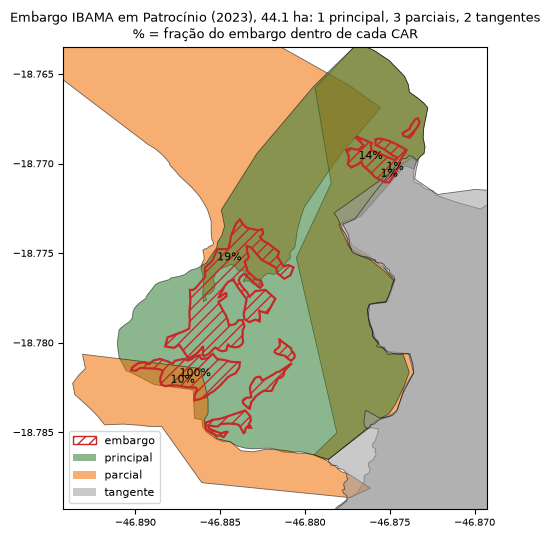

In [18]:
cores = {"principal": "#2e7d32", "parcial": "#ef6c00", "tangente": "#9e9e9e"}
caso = atribuidos[(atribuidos["tipo"] == "embargo IBAMA") & (atribuidos["principal"] == 1)].sort_values(
    "tangente", ascending=False).iloc[0]
g_obj = shapely.from_wkt(objetos.set_index("id_objeto").loc[caso["id_objeto"], "geometria_wkt"])
cars_caso, _ = sicar.consultar_bbox(g_obj.bounds)
fig, ax = plt.subplots(figsize=(6.5, 6))
for p in pares[pares["id_objeto"] == caso["id_objeto"]].itertuples():
    g = shapely.from_wkt(cars_caso.set_index("cod_imovel").loc[p.cod_imovel, "geometria_wkt"])
    desenhar(ax, g, facecolor=cores[p.classe], alpha=0.55, edgecolor="black", linewidth=0.6)
    c = g.intersection(g_obj).representative_point() if g.intersects(g_obj) else g.representative_point()
    ax.annotate(f"{p.fracao_objeto:.0%}", (c.x, c.y), fontsize=8, ha="center")
desenhar(ax, g_obj, facecolor="none", edgecolor="#c62828", hatch="///", linewidth=1.6)
enquadrar(ax, g_obj, 0.004)
ax.set_title(f"Embargo IBAMA em {caso['municipio']} ({pd.Timestamp(caso['data']).year}), {caso['area_ha']:.1f} ha: "
             f"{caso['principal']} principal, {caso['parcial']} parciais, {caso['tangente']} tangentes\n"
             "% = fração do embargo dentro de cada CAR", fontsize=9)
ax.legend(handles=[Patch(facecolor="none", edgecolor="#c62828", hatch="///", label="embargo")]
          + [Patch(facecolor=c, alpha=0.55, label=k) for k, c in cores.items()], loc="lower left", fontsize=8)
plt.show()